# 01 · Exploratory Data Analysis

Looks at the weakly-labeled, deduplicated dataset produced by `python -m src.prepare_data`:

1. how much data survives each cleaning step
2. class balance (overall, per game, per split)
3. message length per class
4. most frequent words per class
5. why deduplication matters

**Content warning:** class 2 is slurs and abuse, so the word lists below contain offensive terms.

In [1]:
import json, sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import FIGURES_DIR, LABELS, PROCESSED_DIR, WITH_DUPS_DIR
from src.plot_style import CLASS_COLORS, SOURCE_COLORS, apply_style
from src.text_utils import tokenize

apply_style()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
splits = {s: pd.read_csv(PROCESSED_DIR / f"{s}.csv") for s in ("train", "val", "test")}
df = pd.concat([d.assign(split=s) for s, d in splits.items()], ignore_index=True)
stats = json.loads((PROCESSED_DIR / "stats.json").read_text())
print(f"{len(df):,} messages total")
df.head()

33,000 messages total


,text,text_norm,label,rule,source,count,split
0,Does anyone really know anyone,does anyone really know anyone,0,none,dota,1,train
1,hopefully ull get cancer,hopefully ull get cancer,2,derog:get cancer,dota,1,train
2,Look our jug,look our jug,0,none,dota,1,train
3,rofl kha?,rofl kha?,0,none,lol,1,train
4,fucking dota 2mm,fucking dota 2mm,1,neg:fuck*,dota,1,train


## 1. Cleaning funnel
Rows left after each step, per game. Dota is capped at its first 5M rows (see `DOTA_MAX_ROWS` in `src/config.py`).

In [2]:
funnel = pd.DataFrame(stats["per_source"]).T[
    ["rows_raw", "rows_nonempty", "rows_not_system", "rows_english", "unique_english"]]
funnel.columns = ["raw", "non-empty", "not system", "English-ish", "unique (dedup)"]
display(funnel.style.format("{:,}"))
print(f"Duplicate rate among English messages: {stats['duplicate_rate']:.1%}")
print("Weak-label counts in the full unique pool (before balancing):")
print(stats["pool_label_counts"])

,raw,non-empty,not system,English-ish,unique (dedup)
lol,"1,697,222","1,697,189","1,696,954","1,600,974","820,696"
dota,"5,000,000","4,998,687","4,998,630","2,855,986","1,079,311"


Duplicate rate among English messages: 58.5%
Weak-label counts in the full unique pool (before balancing):
{'neutral/positive': 1580788, 'negative': 242556, 'derogatory': 28302}


The unique pool is very imbalanced: about 85% neutral and only ~1.5% derogatory. That is why `sample_balanced` draws a fixed number per class to get close to the paper's balance (~43/30/25).

## 2. Class balance

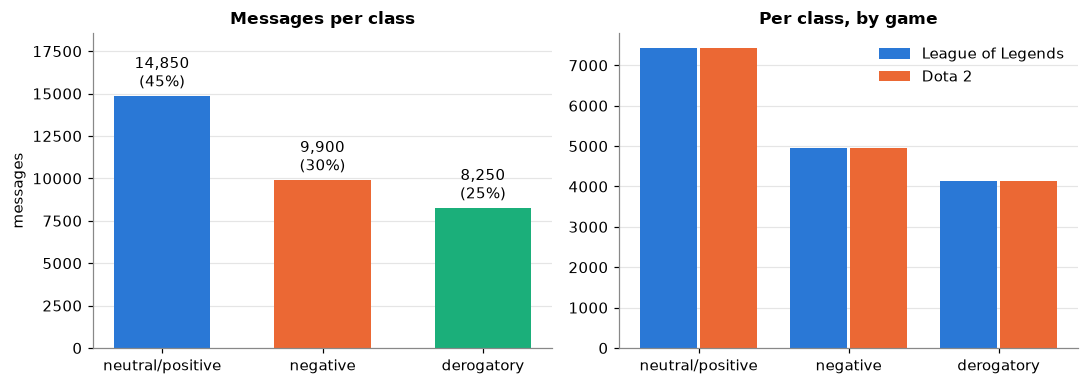

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

counts = df["label"].value_counts().sort_index()
ax = axes[0]
bars = ax.bar([LABELS[i] for i in counts.index], counts.values,
              color=[CLASS_COLORS[i] for i in counts.index], width=0.6)
ax.bar_label(bars, labels=[f"{v:,}\n({v/len(df):.0%})" for v in counts.values], padding=3)
ax.set_title("Messages per class")
ax.set_ylabel("messages")
ax.set_ylim(0, counts.max() * 1.25)
ax.grid(axis="x", visible=False)

ct = pd.crosstab(df["label"], df["source"])[["lol", "dota"]]
ax = axes[1]
w = 0.38
for j, src in enumerate(ct.columns):
    ax.bar([i + (j - 0.5) * (w + 0.02) for i in ct.index], ct[src], width=w,
           color=SOURCE_COLORS[src], label={"lol": "League of Legends", "dota": "Dota 2"}[src])
ax.set_xticks(ct.index, [LABELS[i] for i in ct.index])
ax.set_title("Per class, by game")
ax.legend()
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_class_balance.png")
plt.show()

In [4]:
# Stratified splitting should give the same balance in every split.
pd.crosstab(df["split"], df["label"].map(LABELS), normalize="index").loc[
    ["train", "val", "test"]].style.format("{:.1%}")

label,derogatory,negative,neutral/positive
split,,,
train,25.0%,30.0%,45.0%
val,25.0%,30.0%,45.0%
test,25.0%,30.0%,45.0%


## 3. Message length

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
derogatory,8250.0,4.9,3.1,1.0,3.0,4.0,6.0,28.0
negative,9900.0,4.7,2.8,1.0,3.0,4.0,6.0,27.0
neutral/positive,14850.0,3.9,2.3,1.0,2.0,3.0,5.0,32.0


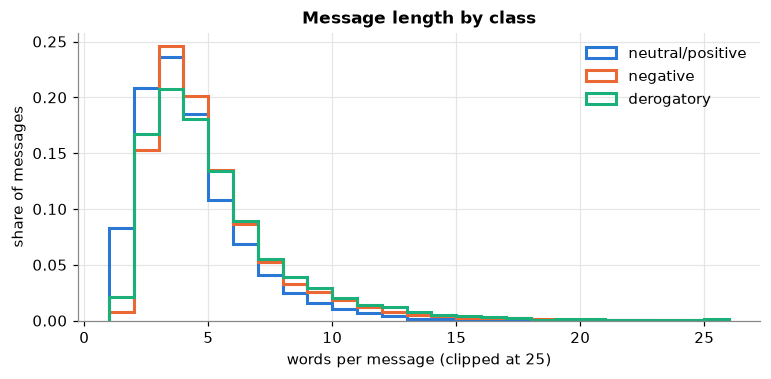

In [5]:
df["n_words"] = df["text_norm"].str.split().str.len()
display(df.groupby(df["label"].map(LABELS))["n_words"].describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.4))
for c in (0, 1, 2):
    vals = df.loc[df["label"] == c, "n_words"].clip(upper=25)
    ax.hist(vals, bins=range(1, 27), histtype="step", linewidth=2,
            color=CLASS_COLORS[c], label=LABELS[c], density=True)
ax.set_xlabel("words per message (clipped at 25)")
ax.set_ylabel("share of messages")
ax.set_title("Message length by class")
ax.legend()
fig.savefig(FIGURES_DIR / "eda_message_length.png")
plt.show()

Neutral messages include more 1-2 word lines ("gg", "ty", "omw"), but the three distributions overlap heavily. Length on its own is a weak signal, and the models have to rely on the words.

## 4. Top words per class
Computed on the training split only, so the test set stays unseen. English stop-words are removed, plus a few chat fillers.

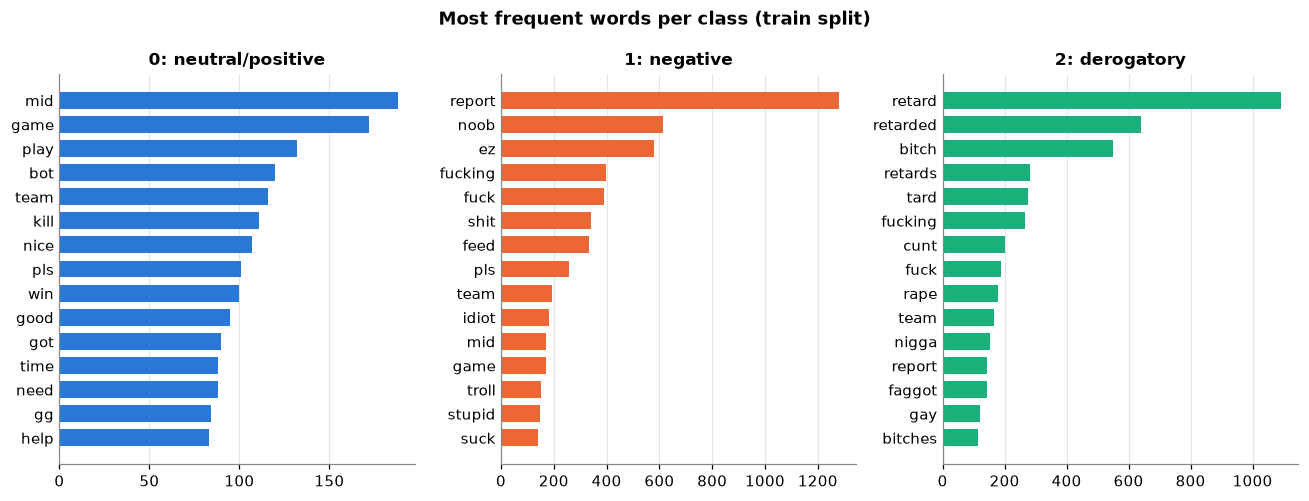

In [6]:
STOP = set(ENGLISH_STOP_WORDS) | {"im", "u", "ur", "dont", "lol", "xd", "just", "like"}
train = splits["train"]

def top_words(texts, n=15):
    c = Counter(w for t in texts for w in tokenize(t) if w not in STOP and len(w) > 1)
    return c.most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for c, ax in zip((0, 1, 2), axes):
    words, freqs = zip(*top_words(train.loc[train["label"] == c, "text_norm"]))
    ax.barh(words[::-1], freqs[::-1], color=CLASS_COLORS[c], height=0.7)
    ax.set_title(f"{c}: {LABELS[c]}")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Most frequent words per class (train split)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_top_words.png")
plt.show()

The class 1 and 2 word lists are mostly the lexicon terms themselves. That is expected because the labels come from those lexicons, but it has a consequence: **models trained here partly learn to re-discover the lexicon**. Test scores measure agreement with the weak labels, not with human judgement. The manual check (`data/manual_check.csv` → `python -m src.label_agreement`) is what tells us how close weak labels are to human labels.

In [7]:
# Which rule produced each training label (top 15)
train["rule"].value_counts().head(15).to_frame("messages")

,messages
rule,
none,9504
derog:retard*,2120
neg:report*,1467
neg:fuck*,969
derog:bitch*,785
neg:noob*,632
neg:ez,559
neg:shit*,352
neg:feed,309


## 5. Why deduplication matters

In [8]:
dups = {s: pd.read_csv(WITH_DUPS_DIR / f"{s}.csv") for s in ("train", "test")}
summary = pd.DataFrame({
    "unique texts in 33k sample": [df["text_norm"].nunique(), stats["with_dups_unique_texts"]],
    "test rows whose exact text is in train": [
        stats["dedup_splits"]["test_rows_seen_in_train"],
        stats["with_dups_splits"]["test_rows_seen_in_train"]],
}, index=["deduplicated (main)", "duplicates kept (side exp.)"])
display(summary.style.format({"unique texts in 33k sample": "{:,}",
                              "test rows whose exact text is in train": "{:.1%}"}))
print("Most repeated messages in the with-duplicates train split:")
dups["train"]["text_norm"].value_counts().head(10)

,unique texts in 33k sample,test rows whose exact text is in train
deduplicated (main),"33,000",0.0%
duplicates kept (side exp.),"23,709",31.6%


Most repeated messages in the with-duplicates train split:


text_norm
ez        561
gg        407
retard    201
lol       169
xd        149
tard      110
gj        109
noob       87
bitch      80
haha       73
Name: count, dtype: int64

Without dedup, about 30% of test messages also appear word-for-word in train, so a model can score well on those just by memorising them. Phase 3 trains on both versions to measure how much this inflates the scores.